# 02 · Tratamento — INMET

**Camada 2 do ETL — Tratamento.** Limpa os dados horários das estações e os agrega para a
escala da vigilância da dengue: **semana epidemiológica**.

| | |
|---|---|
| **Entrada** | `data/01_leitura/inmet/horario/` (≈ 62 milhões de registros horários) |
| **Saída** | `data/02_tratamento/inmet/`: `inmet_diario.parquet`, `inmet_semanal_estacao.parquet`, `estacoes.parquet`, `qualidade_qc.parquet` |
| **Próxima etapa** | `03_integracao_dengue_clima.ipynb` |

**Regras aplicadas**
1. **Controle de qualidade (QC) por limites físicos** — leituras impossíveis de sensor viram `NaN`.
2. Registros duplicados (estação + hora) são removidos.
3. **Agregação diária em hora local (UTC−3)** — as bordas de ano são tratadas juntando os anos.
4. **Completude diária:** um dia só é válido com ≥ 18 das 24 horas medidas.
5. **Agregação semanal (semana epidemiológica)**, exigindo ≥ 4 dias válidos (temperatura/umidade)
   ou ≥ 5 dias válidos (chuva, extrapolada para 7 dias pela média diária).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import epi  # noqa: E402
import viz  # noqa: E402
from config import ANO_FIM, ANO_INICIO, FIGURAS, LEITURA, TRATAMENTO  # noqa: E402

viz.aplicar_estilo()
ENTRADA = LEITURA / "inmet"
SAIDA = TRATAMENTO / "inmet"
SAIDA.mkdir(parents=True, exist_ok=True)

## 1. Limites físicos (QC)

Valores fora destas faixas são fisicamente impossíveis no Brasil ou indicam falha de sensor.
Referências: recorde nacional de temperatura (44,8 °C, Araçuaí/MG, 2023), constante solar
(~4.900 kJ/m² por hora no topo da atmosfera), escala de umidade relativa (0–100%).

In [2]:
LIMITES = pd.DataFrame([
    ("precipitacao_mm", 0, 120, "chuva horária acima de 120 mm não tem registro confiável no país"),
    ("temp_ar_c", -10, 46, "recorde nacional 44,8 °C; mínimas históricas ~ −10 °C (serra catarinense)"),
    ("temp_max_c", -10, 46, "idem"),
    ("temp_min_c", -10, 46, "idem"),
    ("temp_orvalho_c", -20, 35, "ponto de orvalho nunca excede a temperatura do ar"),
    ("umidade_pct", 1, 100, "umidade relativa é um percentual"),
    ("umidade_max_pct", 1, 100, "idem"),
    ("umidade_min_pct", 1, 100, "idem"),
    ("pressao_mb", 700, 1060, "pressão de estação entre o nível do mar e ~3.000 m"),
    ("radiacao_kjm2", 0, 4500, "abaixo da radiação solar máxima possível em 1 hora"),
    ("vento_velocidade_ms", 0, 40, "velocidade média horária"),
    ("vento_rajada_ms", 0, 60, "rajada máxima"),
], columns=["variavel", "minimo", "maximo", "justificativa"])
LIMITES

,variavel,minimo,maximo,justificativa
0,precipitacao_mm,0,120,chuva horária acima de 120 mm não tem registro...
1,temp_ar_c,-10,46,"recorde nacional 44,8 °C; mínimas históricas ~..."
2,temp_max_c,-10,46,idem
3,temp_min_c,-10,46,idem
4,temp_orvalho_c,-20,35,ponto de orvalho nunca excede a temperatura do ar
5,umidade_pct,1,100,umidade relativa é um percentual
6,umidade_max_pct,1,100,idem
7,umidade_min_pct,1,100,idem
8,pressao_mb,700,1060,pressão de estação entre o nível do mar e ~3.0...
9,radiacao_kjm2,0,4500,abaixo da radiação solar máxima possível em 1 ...


## 2. QC + agregação diária (ano a ano)

Para não carregar 62 milhões de linhas de uma vez, cada ano é processado separadamente.
Guardamos somas, contagens e extremos parciais por estação/dia e combinamos no final —
assim o dia 31/12 (que em hora local começa no arquivo de um ano e termina no do seguinte) fica correto.

In [3]:
VARS = LIMITES["variavel"].tolist()
MEDIAS = ["precipitacao_mm", "temp_ar_c", "temp_orvalho_c", "umidade_pct", "pressao_mb", "radiacao_kjm2", "vento_velocidade_ms"]
FUSO_H = -3

qc_registros, parciais = [], []
for ano in range(ANO_INICIO, ANO_FIM + 1):
    h = pd.read_parquet(ENTRADA / "horario" / f"ano={ano}", columns=["codigo_wmo", "datahora_utc", *VARS])
    h["codigo_wmo"] = h["codigo_wmo"].astype(str)
    n0 = len(h)
    h = h.drop_duplicates(["codigo_wmo", "datahora_utc"])
    for _, r in LIMITES.iterrows():
        col = h[r.variavel]
        invalido = col.notna() & ((col < r.minimo) | (col > r.maximo))
        qc_registros.append((ano, r.variavel, int(col.notna().sum()), int(invalido.sum())))
        h.loc[invalido, r.variavel] = np.nan
    h["data"] = (h["datahora_utc"] + pd.Timedelta(hours=FUSO_H)).dt.floor("D")
    g = h.groupby(["codigo_wmo", "data"])
    parciais.append(pd.concat([
        g[MEDIAS].sum(min_count=1).add_suffix("__soma"),
        g[MEDIAS].count().add_suffix("__n"),
        g[["temp_max_c", "umidade_max_pct", "vento_rajada_ms"]].max().add_suffix("__max"),
        g[["temp_min_c", "umidade_min_pct"]].min().add_suffix("__min"),
    ], axis=1).reset_index())
    print(f"{ano}: {n0:>10,} registros | {n0 - len(h):>6,} duplicados".replace(",", "."))

qc = pd.DataFrame(qc_registros, columns=["ano", "variavel", "valores_medidos", "valores_invalidos"])
qc.to_parquet(SAIDA / "qualidade_qc.parquet", index=False)

2014:  4.147.032 registros |      0 duplicados


2015:  4.191.888 registros |      0 duplicados


2016:  4.372.128 registros |      0 duplicados


2017:  4.775.544 registros |      0 duplicados


2018:  5.128.416 registros |      0 duplicados


2019:  5.118.216 registros |      0 duplicados


... (3 outputs left out)

2023:  4.966.920 registros |      0 duplicados


2024:  4.962.960 registros |      0 duplicados


2025:  5.020.248 registros |      0 duplicados


2026:  4.556.568 registros |      0 duplicados


### 2.1 Resultado do QC

In [4]:
qc_var = qc.groupby("variavel")[["valores_medidos", "valores_invalidos"]].sum()
qc_var["pct_invalido"] = qc_var["valores_invalidos"] / qc_var["valores_medidos"] * 100
qc_var = qc_var.sort_values("pct_invalido")
display_qc = qc_var.assign(pct_invalido=qc_var["pct_invalido"].round(4))
display_qc

,valores_medidos,valores_invalidos,pct_invalido
variavel,,,
pressao_mb,50396878,0,0.0000
umidade_max_pct,48444641,0,0.0000
umidade_pct,48508382,0,0.0000
umidade_min_pct,48425018,0,0.0000
vento_velocidade_ms,48184259,1,0.0000
vento_rajada_ms,48129876,1,0.0000
precipitacao_mm,46556751,2,0.0000
temp_max_c,50272600,7179,0.0143
temp_ar_c,50342323,7191,0.0143


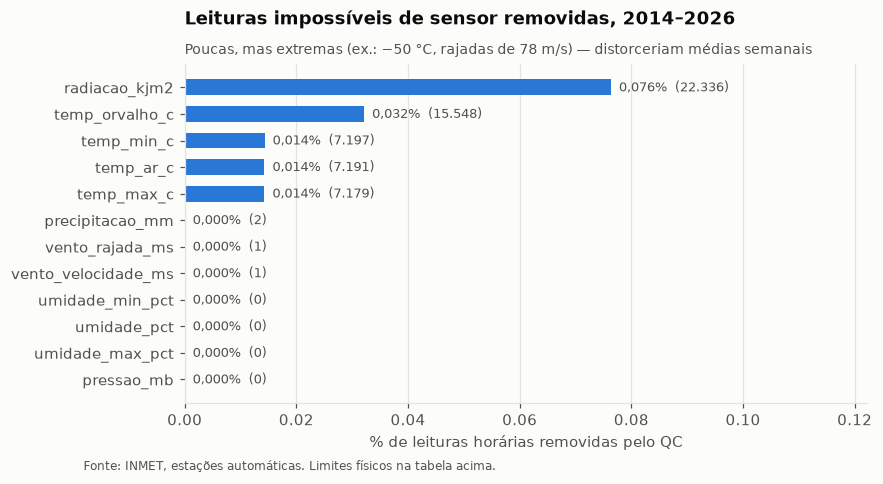

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(qc_var.index, qc_var["pct_invalido"], color=viz.AZUL, height=0.6)
for y, (v, n) in enumerate(zip(qc_var["pct_invalido"], qc_var["valores_invalidos"])):
    ax.text(v, y, f"  {viz.fmt_br(v, 3)}%  ({viz.fmt_br(n)})", va="center", fontsize=8.5, color=viz.TEXTO_2)
ax.set_xlim(0, qc_var["pct_invalido"].max() * 1.6)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("% de leituras horárias removidas pelo QC")
ax.set_title("Leituras impossíveis de sensor removidas, 2014–2026")
viz.subtitulo(ax, "Poucas, mas extremas (ex.: −50 °C, rajadas de 78 m/s) — distorceriam médias semanais")
viz.fonte(fig, "Fonte: INMET, estações automáticas. Limites físicos na tabela acima.")
viz.salvar(fig, "tratamento_inmet_qc", FIGURAS)
plt.show()

## 3. Série diária por estação

In [6]:
p = pd.concat(parciais, ignore_index=True)
g = p.groupby(["codigo_wmo", "data"])
a = pd.concat([g[[c for c in p.columns if c.endswith(("__soma", "__n"))]].sum(min_count=1),
               g[[c for c in p.columns if c.endswith("__max")]].max(),
               g[[c for c in p.columns if c.endswith("__min")]].min()], axis=1)
del p, parciais

HORAS_MIN = 18


def media(v: str) -> pd.Series:
    return (a[f"{v}__soma"] / a[f"{v}__n"].replace(0, np.nan)).astype("float32")


diario = pd.DataFrame(index=a.index)
diario["n_horas_precip"] = a["precipitacao_mm__n"].astype("int16")
diario["n_horas_temp"] = a["temp_ar_c__n"].astype("int16")
diario["n_horas_umidade"] = a["umidade_pct__n"].astype("int16")
ok_p, ok_t, ok_u = (diario[c] >= HORAS_MIN for c in ("n_horas_precip", "n_horas_temp", "n_horas_umidade"))
diario["precipitacao_mm"] = a["precipitacao_mm__soma"].astype("float32").where(ok_p)
diario["temp_media_c"] = media("temp_ar_c").where(ok_t)
diario["temp_max_c"] = a["temp_max_c__max"].astype("float32").where(ok_t)
diario["temp_min_c"] = a["temp_min_c__min"].astype("float32").where(ok_t)
diario["orvalho_media_c"] = media("temp_orvalho_c").where(ok_t)
diario["umidade_media_pct"] = media("umidade_pct").where(ok_u)
diario["umidade_min_pct"] = a["umidade_min_pct__min"].astype("float32").where(ok_u)
diario["pressao_media_mb"] = media("pressao_mb")
diario["radiacao_total_kjm2"] = a["radiacao_kjm2__soma"].astype("float32")
diario["vento_velocidade_media_ms"] = media("vento_velocidade_ms")
diario["vento_rajada_max_ms"] = a["vento_rajada_ms__max"].astype("float32")
diario = diario.reset_index()
diario = diario[diario["data"].dt.year.between(ANO_INICIO - 1, ANO_FIM)]
del a
diario.to_parquet(SAIDA / "inmet_diario.parquet", index=False)

print(f"{len(diario):,} dias-estação | {diario.codigo_wmo.nunique()} estações | "
      f"{diario.data.min():%d/%m/%Y} a {diario.data.max():%d/%m/%Y}".replace(",", "."))
print(f"Dias válidos (≥{HORAS_MIN} h): temperatura {viz.fmt_br(ok_t.mean() * 100, 1)}% | "
      f"chuva {viz.fmt_br(ok_p.mean() * 100, 1)}% | umidade {viz.fmt_br(ok_u.mean() * 100, 1)}%")
diario.describe(percentiles=[0.01, 0.5, 0.99]).T[["count", "min", "1%", "50%", "99%", "max"]].round(1)

2.605.440 dias-estação | 705 estações | 31/12/2013 a 31/10/2026
Dias válidos (≥18 h): temperatura 78,6% | chuva 72,9% | umidade 74,9%


,count,min,1%,50%,99%,max
data,2605440,2013-12-31 00:00:00,2014-02-24 00:00:00,2020-09-05 00:00:00,2026-09-20 00:00:00,2026-10-31 00:00:00
n_horas_precip,2605440.0,0.0,0.0,24.0,24.0,24.0
n_horas_temp,2605440.0,0.0,0.0,24.0,24.0,24.0
n_horas_umidade,2605440.0,0.0,0.0,24.0,24.0,24.0
precipitacao_mm,1900546.0,0.0,0.0,0.0,52.200001,322.200012
temp_media_c,2049031.0,-4.866667,10.0,24.270834,30.5875,37.320835
temp_max_c,2048743.0,-1.2,14.7,30.6,38.700001,45.0
temp_min_c,2048940.0,-9.9,4.6,19.700001,25.700001,34.400002
orvalho_media_c,2001452.0,-19.9,4.408333,18.050001,24.300001,34.200001
umidade_media_pct,1951805.0,7.277778,32.625,74.291664,96.0,100.0


## 4. Série semanal por estação (semana epidemiológica)

In [7]:
se = epi.data_para_semana(diario["data"])
d = pd.concat([diario, se], axis=1)
d = d[d["ano_epi"].between(ANO_INICIO, ANO_FIM)]
d["dia_chuva"] = (d["precipitacao_mm"] >= 1).where(d["precipitacao_mm"].notna())

gs = d.groupby(["codigo_wmo", "id_semana", "ano_epi", "semana_epi"])
semanal = gs.agg(
    n_dias_validos_temp=("temp_media_c", "count"),
    n_dias_validos_precip=("precipitacao_mm", "count"),
    precip_media_diaria=("precipitacao_mm", "mean"),
    precipitacao_max_diaria_mm=("precipitacao_mm", "max"),
    dias_chuva=("dia_chuva", "sum"),
    temp_media_c=("temp_media_c", "mean"),
    temp_max_media_c=("temp_max_c", "mean"),
    temp_min_media_c=("temp_min_c", "mean"),
    temp_max_absoluta_c=("temp_max_c", "max"),
    umidade_media_pct=("umidade_media_pct", "mean"),
    orvalho_media_c=("orvalho_media_c", "mean"),
).reset_index()

ok_sem_t = semanal["n_dias_validos_temp"] >= 4
ok_sem_p = semanal["n_dias_validos_precip"] >= 5
semanal["precipitacao_mm"] = (semanal["precip_media_diaria"] * 7).where(ok_sem_p)
semanal["precipitacao_max_diaria_mm"] = semanal["precipitacao_max_diaria_mm"].where(ok_sem_p)
semanal["dias_chuva"] = semanal["dias_chuva"].where(ok_sem_p)
for c in ["temp_media_c", "temp_max_media_c", "temp_min_media_c", "temp_max_absoluta_c", "umidade_media_pct", "orvalho_media_c"]:
    semanal[c] = semanal[c].where(ok_sem_t)
semanal = semanal.drop(columns="precip_media_diaria")
num = semanal.select_dtypes("float64").columns
semanal[num] = semanal[num].astype("float32")
semanal.to_parquet(SAIDA / "inmet_semanal_estacao.parquet", index=False)
print(f"{viz.fmt_br(len(semanal))} estação-semanas | válidas: temperatura {viz.fmt_br(ok_sem_t.mean() * 100, 1)}%, "
      f"chuva {viz.fmt_br(ok_sem_p.mean() * 100, 1)}%")
semanal.head()

372.465 estação-semanas | válidas: temperatura 78,8%, chuva 72,3%


,codigo_wmo,id_semana,ano_epi,semana_epi,n_dias_validos_temp,n_dias_validos_precip,precipitacao_max_diaria_mm,dias_chuva,temp_media_c,temp_max_media_c,temp_min_media_c,temp_max_absoluta_c,umidade_media_pct,orvalho_media_c,precipitacao_mm
0,A001,201401,2014,1,4,4,NaN,NaN,23.958334,29.700001,17.900000,30.100000,60.833332,14.917708,NaN
1,A001,201402,2014,2,7,7,0.000000,0,22.977978,28.671429,16.842857,29.299999,56.922619,13.394643,0.000000
2,A001,201403,2014,3,7,7,33.200001,3,22.482738,28.300001,17.771429,29.700001,68.065475,15.694643,44.599998
3,A001,201404,2014,4,7,7,43.399998,5,20.132143,26.114286,16.885714,28.299999,84.071426,17.064285,85.199997
4,A001,201405,2014,5,7,7,4.800000,2,21.857143,27.214285,17.371428,28.100000,65.035713,14.517262,6.000000


## 5. Cadastro das estações

In [8]:
meta = pd.read_csv(ENTRADA / "estacoes_por_ano.csv", sep=";", dtype={"codigo_wmo": str})
cobertura = (semanal.groupby("codigo_wmo")
             .agg(semanas_validas_temp=("temp_media_c", "count"), semanas_validas_precip=("precipitacao_mm", "count"),
                  primeira_semana=("id_semana", "min"), ultima_semana=("id_semana", "max")))
estacoes = (meta.sort_values("ano").groupby("codigo_wmo")
            .agg(nome_estacao=("estacao", "last"), sigla_uf=("uf", "last"), regiao_sigla=("regiao", "last"),
                 latitude=("latitude", "last"), longitude=("longitude", "last"), altitude=("altitude", "last"),
                 data_fundacao=("data_fundacao", "first"), primeiro_ano=("ano", "min"), ultimo_ano=("ano", "max"))
            .join(cobertura).reset_index())
estacoes["regiao"] = estacoes["regiao_sigla"].map({"N": "Norte", "NE": "Nordeste", "SE": "Sudeste", "S": "Sul", "CO": "Centro-Oeste"})
estacoes.to_parquet(SAIDA / "estacoes.parquet", index=False)
print(f"{len(estacoes)} estações cadastradas")
estacoes.groupby("regiao").agg(estacoes=("codigo_wmo", "size"),
                               semanas_validas_temp_mediana=("semanas_validas_temp", "median"))

705 estações cadastradas


,estacoes,semanas_validas_temp_mediana
regiao,,
Centro-Oeste,142,427.5
Nordeste,155,458.0
Norte,103,414.0
Sudeste,154,590.0
Sul,151,468.0


### 5.1 Cobertura territorial
A rede de estações automáticas **não é uniforme**: o Norte tem área enorme e poucas estações.
Isso é um viés a declarar — o cruzamento clima × dengue representa melhor Sul, Sudeste e Centro-Oeste.

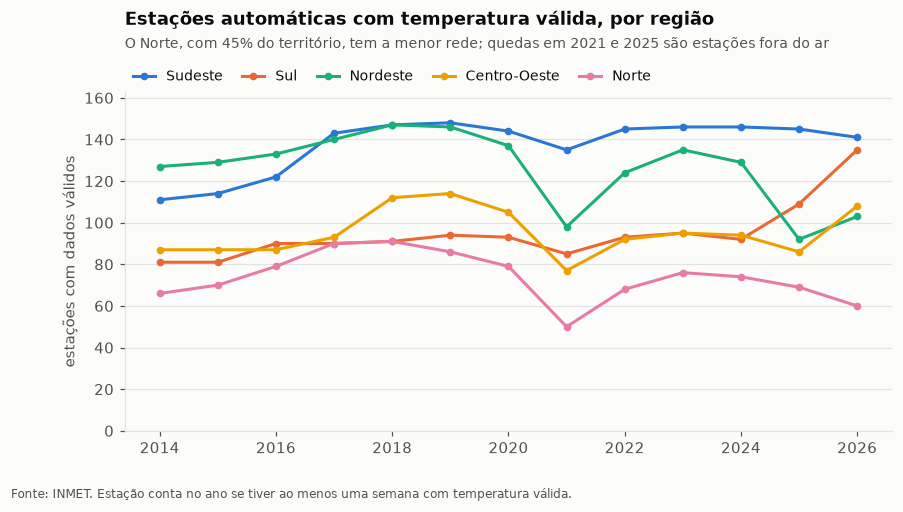

In [9]:
validas = semanal[semanal["temp_media_c"].notna()]
por_ano = (validas.merge(estacoes[["codigo_wmo", "regiao"]]).groupby(["ano_epi", "regiao"])["codigo_wmo"].nunique()
           .unstack())
ordem = ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"]
fig, ax = plt.subplots(figsize=(9, 4))
for i, reg in enumerate(ordem):
    ax.plot(por_ano.index, por_ano[reg], color=viz.CATEGORICA[i], marker="o", markersize=4, label=reg)
ax.set_ylim(0, por_ano.max().max() * 1.1)
ax.set_ylabel("estações com dados válidos")
ax.set_title("Estações automáticas com temperatura válida, por região", pad=44)
ax.text(0, 1.13, "O Norte, com 45% do território, tem a menor rede; quedas em 2021 e 2025 são estações fora do ar",
        transform=ax.transAxes, fontsize=9, color=viz.TEXTO_2)
viz.legenda_topo(ax)
viz.fonte(fig, "Fonte: INMET. Estação conta no ano se tiver ao menos uma semana com temperatura válida.")
viz.salvar(fig, "tratamento_inmet_cobertura", FIGURAS)
plt.show()

### 5.2 Exemplo de série tratada — Brasília (A001)
Dois painéis com o **mesmo eixo de tempo** (e não um gráfico com dois eixos y): a chuva se concentra
entre outubro e abril, quando a temperatura também é mais alta — o "verão chuvoso" favorável ao *Aedes*.

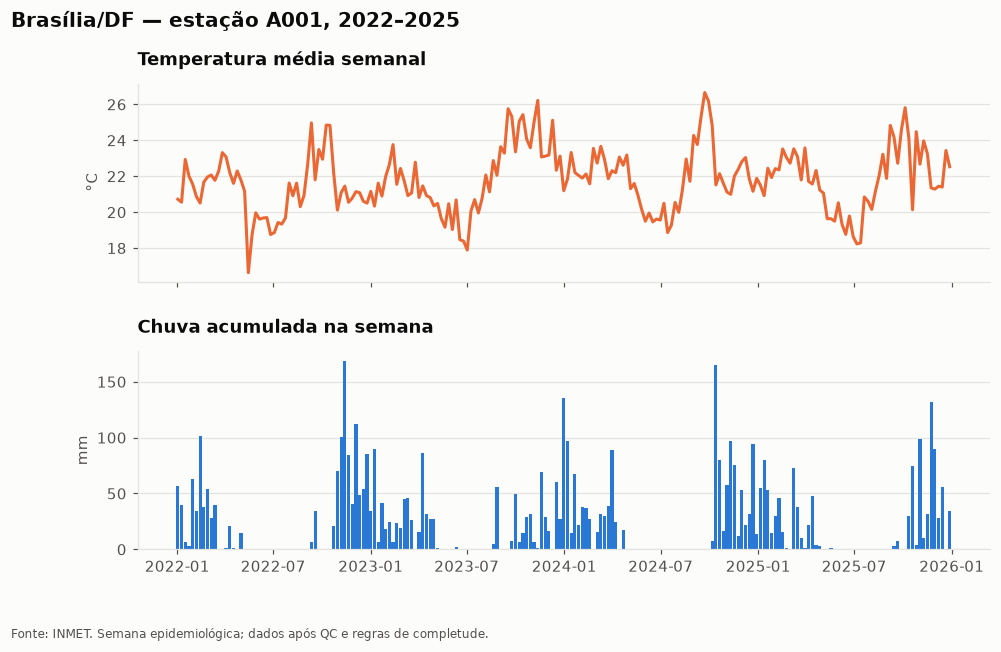

In [10]:
ex = semanal[(semanal.codigo_wmo == "A001") & semanal.ano_epi.between(2022, 2025)].merge(
    epi.calendario(2022, 2025)[["id_semana", "data_inicio"]])
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={"hspace": 0.35})
a1.plot(ex["data_inicio"], ex["temp_media_c"], color=viz.LARANJA)
a1.set_ylabel("°C")
a1.set_title("Temperatura média semanal")
a2.bar(ex["data_inicio"], ex["precipitacao_mm"], width=6, color=viz.AZUL)
a2.set_ylabel("mm")
a2.set_title("Chuva acumulada na semana")
fig.suptitle("Brasília/DF — estação A001, 2022–2025", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.0)
viz.fonte(fig, "Fonte: INMET. Semana epidemiológica; dados após QC e regras de completude.")
viz.salvar(fig, "tratamento_inmet_exemplo_brasilia", FIGURAS)
plt.show()

Próximo passo: **`03_integracao_dengue_clima.ipynb`** — associar estações a municípios e montar o
painel semanal dengue × clima.